# Tabular Data Preprocessing

This notebook covers the customer transaction data and the social-profile data. The aim is to clean both files and combine them so that product category can be used as the prediction target.

The customer IDs require careful checking. The social-profile file contains IDs with an `A` at the beginning, while the transaction file uses numeric IDs. Removing the prefix is tested to see whether the records line up. This is treated as a possible match only and should be confirmed using the dataset documentation.

## 1. Imports and input files

The libraries needed for the checks are imported, and the paths to the two CSV files are set. The files can be placed in `data/raw/` or in the project root.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

def find_file(names):
    candidates = [ROOT / "data" / "raw" / n for n in names] + [ROOT / n for n in names]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError("Could not find: " + ", ".join(names))

tx_path = find_file(["customer_transactions.csv",
                     "customer_transactions - customer_transactions.csv"])
social_path = find_file(["customer_social_profiles.csv",
                         "customer_social_profiles - customer_social_profiles.csv"])

transactions = pd.read_csv(tx_path)
social = pd.read_csv(social_path)
print("Transactions:", transactions.shape, tx_path)
print("Social profiles:", social.shape, social_path)
display(transactions.head())
display(social.head())

Transactions: (150, 6) c:\Users\a\Documents\formative_2_data_processing_personal\data\raw\customer_transactions.csv
Social profiles: (155, 5) c:\Users\a\Documents\formative_2_data_processing_personal\data\raw\customer_social_profiles.csv


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


## 2. Initial data checks

The size of each dataset, column types, missing values and duplicate rows are checked before any changes are made. The number of records in each product category is also reviewed to see whether the target classes are balanced.

--- Transactions ---
Shape: (150, 6)


,dtype
customer_id_legacy,int64
transaction_id,int64
purchase_amount,int64
purchase_date,str
product_category,str
customer_rating,float64


,missing values
customer_id_legacy,0
transaction_id,0
purchase_amount,0
purchase_date,0
product_category,0
customer_rating,10


Exact duplicate rows: 0


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


--- Social profiles ---
Shape: (155, 5)


... (2 outputs left out)

Exact duplicate rows: 5


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


Product category distribution:


,count
product_category,
Sports,35
Electronics,34
Clothing,28
Groceries,28
Books,25


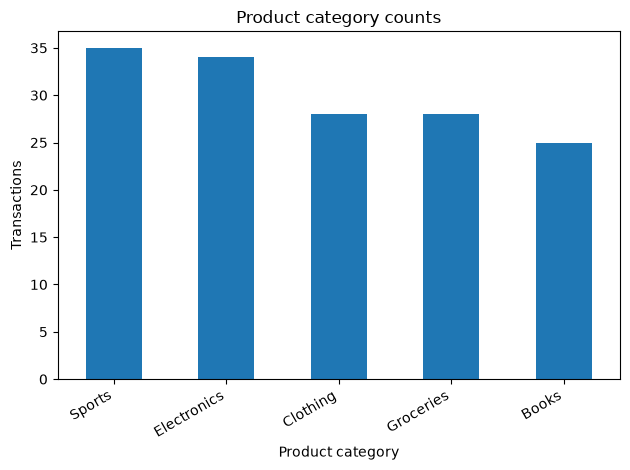

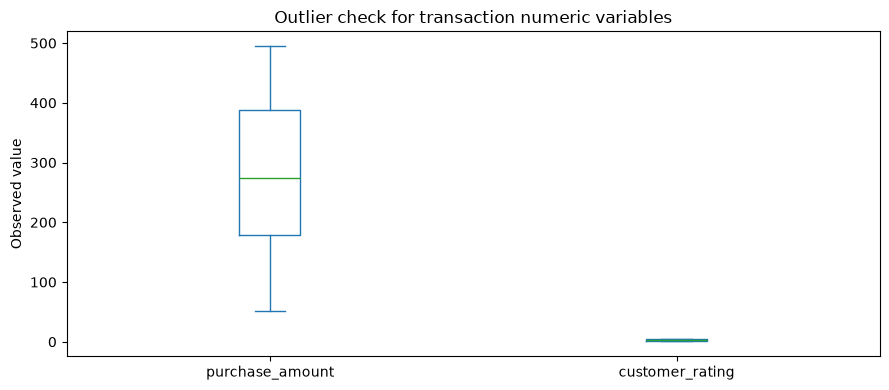

purchase_amount: 0 potential IQR outliers. These values should be checked, not automatically removed.
customer_rating: 0 potential IQR outliers. These values should be checked, not automatically removed.


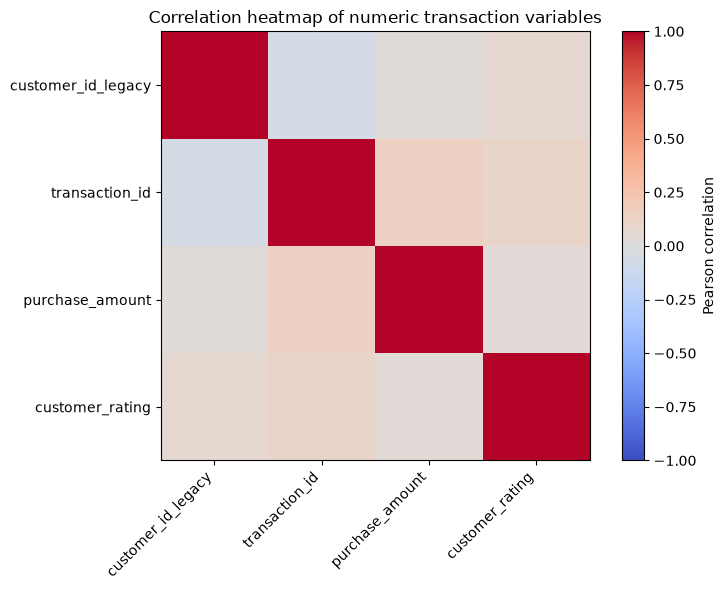

Interpretation: the strongest absolute linear relationship is transaction_id vs purchase_amount (r=0.14). Correlation does not establish causation.
EDA interpretation: the category bar chart shows class balance. The boxplot highlights unusually low or high numeric observations. The heatmap summarises linear relationships among numeric variables.


In [2]:
def audit(df, name):
    print(f"--- {name} ---")
    print("Shape:", df.shape)
    display(df.dtypes.rename("dtype").to_frame())
    display(df.isna().sum().rename("missing values").to_frame())
    print("Exact duplicate rows:", df.duplicated().sum())
    display(df.head())

audit(transactions, "Transactions")
audit(social, "Social profiles")

print("Product category distribution:")
display(transactions["product_category"].value_counts(dropna=False).to_frame("count"))
transactions["product_category"].value_counts().plot(kind="bar", title="Product category counts")
plt.xlabel("Product category")
plt.ylabel("Transactions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

numeric_eda = transactions.select_dtypes(include=np.number).copy()
numeric_eda = numeric_eda.dropna(axis=1, how="all")

fig, ax = plt.subplots(figsize=(9, 4))
outlier_columns = [c for c in ["purchase_amount", "customer_rating"] if c in numeric_eda.columns]
if outlier_columns:
    numeric_eda[outlier_columns].plot(kind="box", ax=ax, showfliers=True)
    ax.set_title("Outlier check for transaction numeric variables")
    ax.set_ylabel("Observed value")
    plt.tight_layout()
    plt.show()
    for column in outlier_columns:
        q1, q3 = numeric_eda[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        outlier_count = ((numeric_eda[column] < q1 - 1.5 * iqr) |
                         (numeric_eda[column] > q3 + 1.5 * iqr)).sum()
        print(f"{column}: {outlier_count} potential IQR outliers. "
              "These values should be checked, not automatically removed.")
else:
    print("No numeric transaction columns were available for the outlier plot.")

if len(numeric_eda.columns) >= 2:
    correlation = numeric_eda.corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(correlation.columns)))
    ax.set_yticks(range(len(correlation.columns)))
    ax.set_xticklabels(correlation.columns, rotation=45, ha="right")
    ax.set_yticklabels(correlation.columns)
    ax.set_title("Correlation heatmap of numeric transaction variables")
    fig.colorbar(image, ax=ax, label="Pearson correlation")
    plt.tight_layout()
    plt.show()
    upper = correlation.where(np.triu(np.ones(correlation.shape), k=1).astype(bool))
    strongest = upper.stack().abs().sort_values(ascending=False)
    if not strongest.empty:
        first_pair = strongest.index[0]
        signed_value = correlation.loc[first_pair[0], first_pair[1]]
        print(f"Interpretation: the strongest absolute linear relationship is "
              f"{first_pair[0]} vs {first_pair[1]} (r={signed_value:.2f}). "
              "Correlation does not establish causation.")
else:
    print("At least two numeric columns are needed for a correlation heatmap.")

print("EDA interpretation: the category bar chart shows class balance. "
      "The boxplot highlights unusually low or high numeric observations. "
      "The heatmap summarises linear relationships among numeric variables.")

## 2.1 Additional exploratory plots

Three EDA views are included: product-category distribution, numeric outlier checks using the IQR rule, and a Pearson correlation heatmap. The printed interpretations describe the observed patterns. Potential outliers are reviewed rather than removed automatically, and correlation is not treated as evidence of causation.

## 3. Check columns and clean data types

The transaction table is used as the main table because each row represents a purchase. Rows without a customer ID or product category cannot be used for the supervised prediction task, so these records are checked and handled here.

In [3]:
required_tx = {"customer_id_legacy", "transaction_id", "purchase_amount",
               "purchase_date", "product_category", "customer_rating"}
required_social = {"customer_id_new", "social_media_platform", "engagement_score",
                   "purchase_interest_score", "review_sentiment"}

assert required_tx.issubset(transactions.columns), f"Missing transaction columns: {required_tx - set(transactions.columns)}"
assert required_social.issubset(social.columns), f"Missing social columns: {required_social - set(social.columns)}"

tx = transactions.copy()
sp = social.copy()

tx["customer_id_legacy"] = tx["customer_id_legacy"].astype("string").str.strip()
sp["customer_id_new"] = sp["customer_id_new"].astype("string").str.strip()
tx["purchase_date"] = pd.to_datetime(tx["purchase_date"], errors="coerce")
tx["product_category"] = tx["product_category"].astype("string").str.strip()

for col in ["purchase_amount", "customer_rating"]:
    tx[col] = pd.to_numeric(tx[col], errors="coerce")
for col in ["engagement_score", "purchase_interest_score"]:
    sp[col] = pd.to_numeric(sp[col], errors="coerce")

print("Missing target rows:", tx["product_category"].isna().sum())
print("Invalid purchase dates:", tx["purchase_date"].isna().sum())
print("Missing transaction customer IDs:", tx["customer_id_legacy"].isna().sum())
print("Missing social customer IDs:", sp["customer_id_new"].isna().sum())

tx = tx.dropna(subset=["customer_id_legacy", "product_category"]).copy()

Missing target rows: 0
Invalid purchase dates: 0
Missing transaction customer IDs: 0
Missing social customer IDs: 0


## 4. Check the customer ID relationship

Transaction IDs are compared with social-profile IDs after one leading `A` is removed. The results show how many IDs match under this assumption and how many records remain unmatched. This is kept as a possible mapping rather than treated as confirmed.

In [4]:
sp["customer_id_candidate"] = sp["customer_id_new"].str.replace(r"^A", "", regex=True)
tx_ids = set(tx["customer_id_legacy"].dropna().astype(str))
social_ids = set(sp["customer_id_candidate"].dropna().astype(str))
overlap = tx_ids & social_ids

print("Unique transaction customers:", len(tx_ids))
print("Unique social customers after candidate normalization:", len(social_ids))
print("Overlapping IDs:", len(overlap))
print("Transaction IDs without social match:", len(tx_ids - social_ids))
print("Social IDs without transaction match:", len(social_ids - tx_ids))
print("Example matches:", sorted(overlap)[:10])

Unique transaction customers: 75
Unique social customers after candidate normalization: 84
Overlapping IDs: 61
Transaction IDs without social match: 14
Social IDs without transaction match: 23
Example matches: ['100', '101', '102', '103', '104', '105', '106', '107', '111', '113']


## 5. Summarise repeated social-profile records

Some customers have more than one social-profile record. The social data is grouped by customer and summary values are calculated before the transaction table is joined. This produces one social-profile row per customer and prevents the merge from multiplying transaction rows.

In [5]:
def stable_mode(values):
    values = values.dropna().astype(str)
    if values.empty:
        return pd.NA
    counts = values.value_counts()
    return sorted(counts[counts == counts.max()].index)[0]

social_customer = sp.groupby("customer_id_candidate").agg(
    social_record_count=("customer_id_new", "size"),
    distinct_platform_count=("social_media_platform", "nunique"),
    engagement_mean=("engagement_score", "mean"),
    engagement_max=("engagement_score", "max"),
    engagement_std=("engagement_score", "std"),
    purchase_interest_mean=("purchase_interest_score", "mean"),
    purchase_interest_max=("purchase_interest_score", "max"),
    purchase_interest_std=("purchase_interest_score", "std"),
    primary_platform=("social_media_platform", stable_mode),
    dominant_sentiment=("review_sentiment", stable_mode),
).reset_index()

platform_flags = pd.crosstab(
    sp["customer_id_candidate"], sp["social_media_platform"]
).gt(0).astype("int8")
platform_flags.columns = [
    "platform_" + str(c).strip().lower().replace(" ", "_")
    for c in platform_flags.columns
]
platform_flags = platform_flags.reset_index()
social_customer = social_customer.merge(
    platform_flags, on="customer_id_candidate", validate="one_to_one"
)

print("Social records:", len(sp))
print("Customer-level social rows:", len(social_customer))
print("Unique customer keys:", social_customer["customer_id_candidate"].is_unique)
display(social_customer.head())

Social records: 155
Customer-level social rows: 84
Unique customer keys: True


,customer_id_candidate,social_record_count,distinct_platform_count,engagement_mean,engagement_max,engagement_std,purchase_interest_mean,purchase_interest_max,purchase_interest_std,primary_platform,dominant_sentiment,platform_facebook,platform_instagram,platform_linkedin,platform_tiktok,platform_twitter
0,100,2,2,77.000000,81,5.656854,4.400000,4.4,0.000000,Instagram,Negative,0,1,0,0,1
1,101,1,1,68.000000,68,NaN,1.000000,1.0,NaN,Twitter,Neutral,0,0,0,0,1
2,102,1,1,51.000000,51,NaN,4.800000,4.8,NaN,LinkedIn,Neutral,0,0,1,0,0
3,103,3,2,64.333333,77,10.969655,2.866667,3.6,0.665833,Instagram,Positive,1,1,0,0,0
4,104,3,2,83.000000,91,7.549834,2.933333,4.6,1.527525,Twitter,Negative,1,0,0,0,1


## 6. Merge the datasets and check the result

A left join is used so that valid transactions are kept even when a customer does not have a matching social profile. The join is also validated as many-to-one because the social data should now contain one row per customer.

In [6]:
merged = tx.merge(
    social_customer,
    left_on="customer_id_legacy",
    right_on="customer_id_candidate",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Transaction rows before merge:", len(tx))
print("Rows after merge:", len(merged))
print("Matched transaction rows:", (merged["_merge"] == "both").sum())
print("Unmatched transaction rows:", (merged["_merge"] == "left_only").sum())
print("Unique transaction IDs after merge:", merged["transaction_id"].nunique())

assert len(merged) == len(tx), "The merge changed the transaction row count."
assert merged["transaction_id"].is_unique, "Transaction IDs are duplicated after merge."

merged = merged.drop(columns=["customer_id_candidate", "_merge"])

Transaction rows before merge: 150
Rows after merge: 150
Matched transaction rows: 117
Unmatched transaction rows: 33
Unique transaction IDs after merge: 150


## 7. Prepare the model features

The target column is `product_category`. Transaction and customer identifiers are removed from the predictors. Purchase amount and customer rating are also excluded because these values may only be available after the purchase, which would not be suitable for a prediction made beforehand.

In [7]:
target = "product_category"
merged["purchase_year"] = merged["purchase_date"].dt.year
merged["purchase_month"] = merged["purchase_date"].dt.month
merged["purchase_dayofweek"] = merged["purchase_date"].dt.dayofweek

excluded = {
    "transaction_id", "customer_id_legacy", "customer_id_candidate",
    "purchase_date", "purchase_amount", "customer_rating", target
}
feature_columns = [c for c in merged.columns if c not in excluded]

model_table = merged[feature_columns + [target]].copy()
print("Feature columns:", feature_columns)
print("Target classes:", sorted(model_table[target].dropna().astype(str).unique()))
display(model_table.head())

class_counts = model_table[target].value_counts()
display(pd.concat([
    class_counts.rename("count"),
    (class_counts / class_counts.sum() * 100).round(1).rename("percent")
], axis=1))

social_cols = [c for c in social_customer.columns if c != "customer_id_candidate"]
display(merged[social_cols].isna().mean().sort_values(ascending=False)
        .rename("missing_fraction").to_frame())

Feature columns: ['social_record_count', 'distinct_platform_count', 'engagement_mean', 'engagement_max', 'engagement_std', 'purchase_interest_mean', 'purchase_interest_max', 'purchase_interest_std', 'primary_platform', 'dominant_sentiment', 'platform_facebook', 'platform_instagram', 'platform_linkedin', 'platform_tiktok', 'platform_twitter', 'purchase_year', 'purchase_month', 'purchase_dayofweek']
Target classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']


,social_record_count,distinct_platform_count,engagement_mean,engagement_max,engagement_std,purchase_interest_mean,purchase_interest_max,purchase_interest_std,primary_platform,dominant_sentiment,platform_facebook,platform_instagram,platform_linkedin,platform_tiktok,platform_twitter,purchase_year,purchase_month,purchase_dayofweek,product_category
0,3.0,2.0,71.666667,82.0,10.503968,2.166667,3.6,1.250333,Twitter,Neutral,0.0,0.0,0.0,1.0,1.0,2024,1,0,Sports
1,1.0,1.0,60.000000,60.0,NaN,4.300000,4.3,NaN,Instagram,Positive,0.0,1.0,0.0,0.0,0.0,2024,1,1,Electronics
2,1.0,1.0,87.000000,87.0,NaN,4.800000,4.8,NaN,Facebook,Negative,1.0,0.0,0.0,0.0,0.0,2024,1,2,Electronics
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2024,1,3,Clothing
4,3.0,3.0,72.666667,89.0,16.502525,2.500000,2.9,0.458258,Instagram,Neutral,0.0,1.0,1.0,1.0,0.0,2024,1,4,Clothing


,count,percent
product_category,,
Sports,35,23.3
Electronics,34,22.7
Clothing,28,18.7
Groceries,28,18.7
Books,25,16.7


,missing_fraction
engagement_std,0.58
purchase_interest_std,0.58
distinct_platform_count,0.22
engagement_mean,0.22
engagement_max,0.22
purchase_interest_mean,0.22
social_record_count,0.22
purchase_interest_max,0.22
primary_platform,0.22
dominant_sentiment,0.22


## 8. Save the processed files

The cleaned tables, merged dataset and model feature table are saved in `data/processed/`. The original CSV files are left unchanged so that the preprocessing steps can be repeated if needed.

In [8]:
output_dir = ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

tx.to_csv(output_dir / "transactions_clean.csv", index=False)
social_customer.to_csv(output_dir / "social_profiles_customer_level.csv", index=False)
merged.to_csv(output_dir / "customer_transactions_social_merged.csv", index=False)
model_table.to_csv(output_dir / "tabular_model_features.csv", index=False)

print("Saved processed files:")
for path in sorted(output_dir.glob("*.csv")):
    print("-", path)

Saved processed files:
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\customer_transactions_social_merged.csv
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\social_profiles_customer_level.csv
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\tabular_model_features.csv
- c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\transactions_clean.csv


## 9. Final checks

Final checks are carried out to make sure the merge did not increase the number of transaction rows unexpectedly and that the target column is still available for modelling.

In [9]:
summary = pd.Series({
    "input_transaction_rows": len(transactions),
    "transaction_rows_after_cleaning": len(tx),
    "merged_transaction_rows": len(merged),
    "unique_transaction_ids_after_merge": merged["transaction_id"].nunique(),
    "unique_transaction_customers": merged["customer_id_legacy"].nunique(),
    "social_customer_rows_after_aggregation": len(social_customer),
    "social_customer_keys_unique": social_customer["customer_id_candidate"].is_unique,
    "missing_target_after_cleaning": merged[target].isna().sum(),
    "matched_transaction_rows": int(merged[social_cols].notna().any(axis=1).sum()),
    "unmatched_transaction_rows": int(merged[social_cols].isna().all(axis=1).sum()),
})
display(summary.to_frame("value"))

assert len(merged) == len(tx)
assert merged["transaction_id"].is_unique
assert social_customer["customer_id_candidate"].is_unique
assert merged[target].notna().all()
print("Tabular preprocessing completed.")

,value
input_transaction_rows,150
transaction_rows_after_cleaning,150
merged_transaction_rows,150
unique_transaction_ids_after_merge,150
unique_transaction_customers,75
social_customer_rows_after_aggregation,84
social_customer_keys_unique,True
missing_target_after_cleaning,0
matched_transaction_rows,117
unmatched_transaction_rows,33


Tabular preprocessing completed.


## 10. What this notebook covers

This notebook completes the customer-data preparation part of the assignment. It does not cover the image or audio data. Those are handled in separate notebooks using the group's collected samples.

The next steps are to prepare the facial images, process the voice recordings, and then train and evaluate the three models.